# Notebook 01: Experiment 1, the spare seat (three seeds)

Companion to the Experiment 1 subsection of the report.

Design: the paper's independent Gaussian setting with every style coordinate changing in every pair ($p = 1$), so that each price equals the augmentation variance; the augmentation standard deviation of style coordinate 1 is swept over $\sigma_1 \in \{0.01, 0.03, 0.1, 0.3, 1\}$ (prices $10^{-4}$ to $1$) while $s_2, \dots, s_5$ keep $\sigma = 1$; the encoder has $d = n_c + 1 = 6$ outputs; two controls use $d = 5$ at $\sigma_1 = 0.01$ and $\sigma_1 = 1$; one seed; 10,000 updates per run. Part A of the code cell is a linear toy on the latents themselves (seconds); Part B is the full pipeline, scored per coordinate. Outputs: the per-coordinate $R^2$ table, `extension_soft_content/retention_curve.png` (the Experiment 1 figure of the report) and `results.csv`.

This is one of seven notebooks obtained by splitting the single working notebook `main_mlp_explained.ipynb` by experiment, following the experiments of the comprehensive-exam report on von Kügelgen et al. (NeurIPS 2021):

| Notebook | Report section |
|---|---|
| 00 | Implementation; reproduction of the paper's experiment at a reduced budget |
| 01 | Experiment 1: the spare seat |
| 02 | Experiment 2: content recovery under perturbation |
| 03 | Experiment 3: a non-Gaussian world |
| 04 | Experiment 4: what decides the finite-budget outcome |
| 05 | Experiment 5: nonlinear representations and invariant functions of style |
| A1 | Supplementary runs not used in the report |

Every notebook runs on its own, top to bottom: Part A repeats the shared setup cells of notebook 00 verbatim, Part B holds the experiment. Saved outputs are carried over from the working notebook wherever a cell's source is unchanged; cells whose source was adjusted have no saved outputs and say so. Training runs are cached as files under the experiment's results folder, so a cell can be rerun and resumes from what is already there; choose a persistent location for that folder on Colab.

Notes on this notebook (three-seed version): `SWEEP_SEEDS = [0, 1, 2]`, so every point of the sweep and both controls are trained three times, $7 \times 3 = 21$ encoder trainings at 10,000 updates (minutes each on a GPU). A seed sets the mixing network, the encoder initialisation, the training stream and the probe samples together, as in notebook 00 and the paper's script, so the spread over seeds includes the draw of the mixing network. Relative to the one-seed cell: the linear toy also runs per seed and reports the mean loading; the tables give mean ± sample sd over seeds (per coordinate, and for the three block summaries drawn in the figure) and are saved as CSV files beside the per-run `results.csv`; the figure carries error bars on every curve. The code is unchanged otherwise. Runs are cached by (sigma1, d, seed, steps) under `extension_soft_content/`, so a cached seed 0 is reused and only the new seeds train; outputs were cleared because the cell's source changed.


## Part A: shared setup (identical in every notebook)

The cells of this part define the paper's simulation: the latent world, the augmentation at the latent level, the frozen mixing network, the encoder and the contrastive objective. They are copied verbatim from notebook 00, where each step is explained. Run them first; Part B uses `cfg`, `device`, `Settings`, `make_world`, `make_mixing`, `make_encoder` and `contrastive_loss` from here. The demonstration setting is `independent_partial`; each experiment overrides what it changes through `replace(cfg, ...)`.


## 2. Setup and settings

Use a Python 3.10+ notebook kernel. If an import is missing, uncomment the installation line, run it, and restart the kernel if requested. PyTorch can use an available NVIDIA GPU or Apple Silicon GPU; CPU also works. Numerical results can differ across devices and software versions.

In [1]:
import copy
import math
import platform
import time
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import wishart
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

import torch
from torch import nn
from IPython.display import display

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelsize": 11, "axes.titlesize": 12, "font.size": 10,
})

versions = {
    "Python": platform.python_version(), "PyTorch": torch.__version__,
    "NumPy": np.__version__, "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}
display(pd.Series(versions, name="Version").to_frame())

,Version
Python,3.13.16
PyTorch,2.11.0+cu130
NumPy,2.1.3
SciPy,1.16.3
scikit-learn,1.6.1


The four named scenarios correspond to the progression in §5.1. Start with `independent_partial`, then change one setting at a time and rerun from this cell.

| Scenario | Chance each style coordinate changes | Dependence within blocks | Style depends on content |
|---|---:|---|---|
| `independent_all` | 1.00 | No | No |
| `independent_partial` | 0.75 | No | No |
| `dependent_blocks` | 0.75 | Yes | No |
| `content_causes_style` | 0.75 | Yes | Yes |

`content_dim` and `style_dim` describe the simulated world. `representation_dim` describes the encoder's output. The standard setting makes the output dimension equal to the content dimension.

`steps` is the number of parameter updates. Every update uses fresh simulated data. `batch_size` controls both the number of positive pairs and the size of the independent negative pool. Each anchor is compared with every item in that pool.

In [2]:
SCENARIO = "independent_partial"

SCENARIOS = {
    "independent_all":      (1.00, False, False),
    "independent_partial":  (0.75, False, False),
    "dependent_blocks":     (0.75, True,  False),
    "content_causes_style": (0.75, True,  True),
}

@dataclass
class Settings:
    seed: int = 7                          # Controls randomness so a run can be repeated.
    content_dim: int = 5                   # Number of true content variables, unchanged across paired views.
    style_dim: int = 5                     # Number of true style variables, which may change across views.
    representation_dim: int = 5            # Number of encoder outputs; equals content_dim.
    style_change_prob: float = 0.75        # Probability that each style coordinate is selected for change ("Biased Coin")
    statistical_dependence: bool = False   # If True, allow correlations within content, style noise, and augmentation noise.
    content_dependent_style: bool = False  # If True, generate style as s = a + Bc + noise.
    marginal_std: float = 1.0              # Standard deviation of content and residual style noise when dependence is off.
    style_noise_std: float = 1.0           # Standard deviation of noise added to selected style coordinates when dependence is off.
    mixing_layers: int = 3                 # Number of linear layers in the fixed latent-to-observation network.
    condition_pool: int = 25000            # Number of random matrices used to estimate a conditioning threshold.
    condition_quantile: float = 0.001      # Set the threshold using roughly the best-conditioned 0.1% of those matrices.
    learning_rate: float = 1e-4            # Controls the size of the encoder's parameter updates during training.
    temperature: float = 1.0               # Scales distances in the contrastive loss; smaller values sharpen comparisons.
    batch_size: int = 1024                  # Positive pairs per update; also the number of independent negative examples.
    steps: int = 10000                      # Total number of encoder parameter updates.
    log_every: int = 200                   # Print training progress every this many updates.
    probe_train_size: int = 3000            # Examples used to fit evaluation models that predict latents from representations.
    probe_test_size: int = 5000            # Separate examples used to test those evaluation models.
    device: str = "auto"                   # Automatically choose CUDA, then MPS, then CPU; can also set one explicitly.

cfg = Settings()
(cfg.style_change_prob, cfg.statistical_dependence,
 cfg.content_dependent_style) = SCENARIOS[SCENARIO]

# Original script's training scale (not enabled for this demonstration):
# cfg.batch_size = 6144
# cfg.steps = 100001
# The original nonlinear evaluation fits probes on 5 * 4096 examples and
# evaluates on 10 fresh batches of 4096. Kernel regression at that size is costly.

assert min(cfg.content_dim, cfg.style_dim, cfg.representation_dim) >= 1
assert 0 <= cfg.style_change_prob <= 1
assert min(cfg.marginal_std, cfg.style_noise_std, cfg.temperature) > 0
assert cfg.steps > 0 and cfg.batch_size > 1

if cfg.device != "auto":
    device = torch.device(cfg.device)
elif torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

torch.manual_seed(cfg.seed)
torch.set_num_threads(2)  # Avoid oversubscribing CPU cores in small examples.
latent_dim = cfg.content_dim + cfg.style_dim
print(f"Scenario: {SCENARIO}; device: {device}")
display(pd.Series(asdict(cfg), name="Setting").to_frame())

Scenario: independent_partial; device: cuda


,Setting
seed,7
content_dim,5
style_dim,5
representation_dim,5
style_change_prob,0.75
statistical_dependence,False
content_dependent_style,False
marginal_std,1.0
style_noise_std,1.0
mixing_layers,3


## 3. Build the latent world

We first draw content, then draw style:
$
c\sim N(0,\Sigma_c),\qquad
s=a+Bc+\varepsilon_s,\qquad
\varepsilon_s\sim N(0,\Sigma_s),
$
with independent content and residual draws.

If `statistical_dependence=False`, the covariance matrices are diagonal. If it is `True`, we generate covariance matrices that allow coordinates within each block to be correlated. A Wishart draw is simply a convenient way to generate a positive definite covariance matrix.

If `content_dependent_style=False`, we set $(a=0)$ and $(B=0)$. Otherwise, $(a+Bc)$ makes the distribution of style depend on content. This implements the paper's example of content influencing style.

The covariance matrices and $(a,B)$ are drawn once and then kept fixed. We repeatedly sample new people or objects from this same artificial world.

In [3]:
def make_world(settings):
    """Create fixed parameters of the data distribution on the CPU."""
    rng = np.random.default_rng(settings.seed)
    nc, ns = settings.content_dim, settings.style_dim

    def covariance(dim, std):
        if settings.statistical_dependence:
            # Match the intended Wishart construction in the original experiment.
            matrix = np.atleast_2d(wishart.rvs(df=dim, scale=np.eye(dim), random_state=rng))
        else:
            matrix = (std ** 2) * np.eye(dim)
        return torch.tensor(matrix, dtype=torch.float64)

    Sigma_c = covariance(nc, settings.marginal_std)
    Sigma_s = covariance(ns, settings.marginal_std)
    Sigma_aug = covariance(ns, settings.style_noise_std)
    # As in upstream spaces.py, explicit covariances supersede the std arguments.
    a = torch.zeros(ns)
    B = torch.zeros(ns, nc)
    if settings.content_dependent_style:
        a = torch.tensor(rng.standard_normal(ns), dtype=torch.float32)
        B = torch.tensor(rng.standard_normal((ns, nc)), dtype=torch.float32)
    return {
        "L_c": torch.linalg.cholesky(Sigma_c).float(),
        "L_s": torch.linalg.cholesky(Sigma_s).float(),
        "L_aug": torch.linalg.cholesky(Sigma_aug).float(),
        "a": a, "B": B,
    }

world = make_world(cfg)

def sample_latents(size, generator):
    """Draw z=(c,s). Latent values are used by the simulator and evaluator."""
    c = torch.randn(size, cfg.content_dim, generator=generator) @ world["L_c"].T
    eps_s = torch.randn(size, cfg.style_dim, generator=generator) @ world["L_s"].T
    s = world["a"] + c @ world["B"].T + eps_s
    return torch.cat([c, s], dim=1)

display(pd.DataFrame({
    "block": ["content", "style residual", "augmentation noise"],
    "dimension": [cfg.content_dim, cfg.style_dim, cfg.style_dim],
    "covariance": ["L_c @ L_c.T", "L_s @ L_s.T", "L_aug @ L_aug.T"],
}))

,block,dimension,covariance
0,content,5,L_c @ L_c.T
1,style residual,5,L_s @ L_s.T
2,augmentation noise,5,L_aug @ L_aug.T


For each original example, choose which style coordinates change using independent Bernoulli draws:
$
M_j\sim\mathrm{Bernoulli}(p),\qquad
\widetilde s=s+M\odot\eta,\qquad
\eta\sim N(0,\Sigma_{\mathrm{aug}}).
$
The symbol $(\odot)$ means coordinatewise multiplication. Content is copied exactly. A style coordinate whose mask equals zero is also copied exactly. The selected subset \(A\) is the set of coordinates whose masks equal one.

We additionally generate independent examples for the negative pool. They come from the same original latent distribution; they are not paired with the anchors.

When $(p>0)$ and the noise covariance is positive definite, each style coordinate has a chance to vary locally. Setting $(p=0)$ removes this property and changes the identification problem.

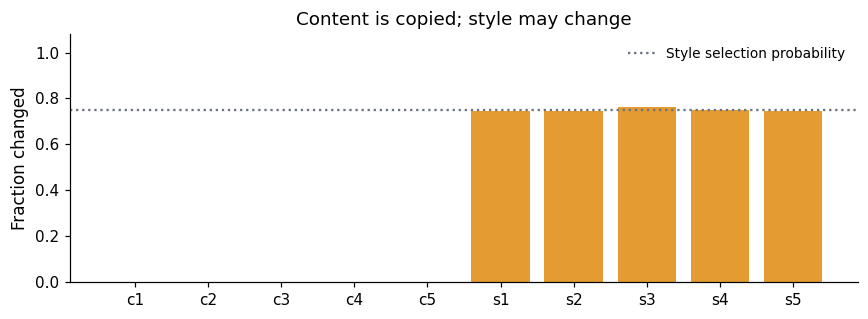

In [4]:
def augment_latents(z, generator):
    nc = cfg.content_dim
    style = z[:, nc:]
    mask = (torch.rand(style.shape, generator=generator) < cfg.style_change_prob)
    noise = torch.randn(style.shape, generator=generator) @ world["L_aug"].T
    changed_style = style + mask * noise
    return torch.cat([z[:, :nc], changed_style], dim=1)

def sample_triplet(size, generator):
    z = sample_latents(size, generator)
    z_negative = sample_latents(size, generator)
    z_augmented = augment_latents(z, generator)
    return z, z_augmented, z_negative

# A separate random stream keeps this inspection from changing training data.
inspection_rng = torch.Generator().manual_seed(cfg.seed + 10)
z_check, z_aug_check, _ = sample_triplet(5000, inspection_rng)
assert torch.equal(z_check[:, :cfg.content_dim], z_aug_check[:, :cfg.content_dim])
change_rates = (z_check != z_aug_check).float().mean(dim=0).numpy()
names = ([f"c{i+1}" for i in range(cfg.content_dim)] +
         [f"s{i+1}" for i in range(cfg.style_dim)])

fig, ax = plt.subplots(figsize=(8, 3))
colors = ["#227c9d"] * cfg.content_dim + ["#e49b32"] * cfg.style_dim
ax.bar(names, change_rates, color=colors)
ax.axhline(cfg.style_change_prob, color="#6b7280", linestyle=":", label="Style selection probability")
ax.set(ylim=(0, 1.08), ylabel="Fraction changed", title="Content is copied; style may change")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 4. Hide the latents behind a fixed mixing network

The mixing network converts $(z)$ into $(x)$. It has square, invertible weight matrices and LeakyReLU activations with a nonzero negative slope. Its input and output both have dimension $(n_c+n_s)$, as in this particular synthetic experiment.

The condition number measures how unevenly a matrix stretches different directions. The code samples candidate matrices and keeps well-conditioned ones. This reduces severe numerical distortion; it is not a training step.

The mixing parameters are frozen. Only the encoder will be trained. LeakyReLU is invertible here but has a kink at zero, so this implementation is not literally smooth everywhere as required by the theorems.

In [5]:
def make_mixing(settings):
    """Adapt the upstream well-conditioned, square mixing MLP."""
    n = settings.content_dim + settings.style_dim
    rng = np.random.default_rng(settings.seed + 100)

    def candidate():
        matrix = rng.uniform(-1, 1, size=(n, n))
        return matrix / np.linalg.norm(matrix, axis=0, keepdims=True)

    conditions = np.array([
        np.linalg.cond(candidate()) for _ in range(settings.condition_pool)
    ])
    threshold = np.sort(conditions)[int(settings.condition_pool * settings.condition_quantile)]
    modules, accepted_conditions = [], []
    for layer in range(settings.mixing_layers):
        matrix = candidate()
        while np.linalg.cond(matrix) > threshold:
            matrix = candidate()
        linear = nn.Linear(n, n, bias=False)
        with torch.no_grad():
            linear.weight.copy_(torch.tensor(matrix, dtype=torch.float32))
        modules.append(linear)
        accepted_conditions.append(np.linalg.cond(matrix))
        if layer < settings.mixing_layers - 1:
            modules.append(nn.LeakyReLU(negative_slope=0.2))
    network = nn.Sequential(*modules).to(device)
    network.requires_grad_(False)
    network.eval()
    return network, accepted_conditions

mixing, condition_numbers = make_mixing(cfg)
print("Mixing layer condition numbers:", np.round(condition_numbers, 2))
print("Mixing parameters trainable:", any(p.requires_grad for p in mixing.parameters()))

with torch.no_grad():
    x_check = mixing(z_check[:5].to(device))
print("Latent shape:", tuple(z_check[:5].shape))
print("Observation shape:", tuple(x_check.shape))

Mixing layer condition numbers: [4.56 4.26 4.91]
Mixing parameters trainable: False
Latent shape: (5, 10)
Observation shape: (5, 10)


The encoder receives the mixed observation and outputs \(k\) numbers, where `representation_dim = k`. We preserve the original script's hidden-layer widths and activations.

With the default dimensions, the learned mapping is $(g:\mathbb R^{10}\to\mathbb R^5)$. It cannot invert the full observation. The desired result is an invertible representation of the five-dimensional content block after discarding additional style variation.

In [6]:
def make_encoder(settings):
    n = settings.content_dim + settings.style_dim
    # Same hidden widths as main_mlp.py; final layer has no activation.
    widths = [n, n * 10, n * 50, n * 50, n * 50, n * 50, n * 10,
              settings.representation_dim]
    modules = []
    for i, (n_in, n_out) in enumerate(zip(widths[:-1], widths[1:])):
        modules.append(nn.Linear(n_in, n_out))
        if i < len(widths) - 2:
            modules.append(nn.LeakyReLU(negative_slope=0.01))
    return nn.Sequential(*modules).to(device)

torch.manual_seed(cfg.seed + 200)
encoder = make_encoder(cfg)
initial_encoder = copy.deepcopy(encoder).eval()
print(encoder)
print("Trainable encoder parameters:", sum(p.numel() for p in encoder.parameters()))

Sequential(
  (0): Linear(in_features=10, out_features=100, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Linear(in_features=100, out_features=500, bias=True)
  (3): LeakyReLU(negative_slope=0.01)
  (4): Linear(in_features=500, out_features=500, bias=True)
  (5): LeakyReLU(negative_slope=0.01)
  (6): Linear(in_features=500, out_features=500, bias=True)
  (7): LeakyReLU(negative_slope=0.01)
  (8): Linear(in_features=500, out_features=500, bias=True)
  (9): LeakyReLU(negative_slope=0.01)
  (10): Linear(in_features=500, out_features=100, bias=True)
  (11): LeakyReLU(negative_slope=0.01)
  (12): Linear(in_features=100, out_features=5, bias=True)
)
Trainable encoder parameters: 853705


## 5. The contrastive objective

Let $(u_i=g(x_i))$, $(v_i=g(\widetilde x_i))$, and $(w_j=g(x_j^-))$. The first two form a positive pair. The $(w_j)$'s are encoded observations from the independent negative pool.

For the original loss's default settings, define
$
d_i^+=\|u_i-v_i\|^2,\qquad d_{ij}^-=\|u_i-w_j\|^2.
$
With batch size $(m)$ and temperature $(\tau)$, the loss is
$
\frac1m\sum_i\left[
\frac{d_i^+}{\tau}
+\log\left\{\frac{e^{-d_i^+/\tau}+\sum_{j=1}^m e^{-d_{ij}^-/\tau}}{m+1}\right\}
\right].
$

The first term encourages paired representations to agree. The second makes mapping everything to the same point unattractive: independent examples can instead be separated while positive pairs remain close. Both effects depend on the same learned representation.

This is the squared-distance, InfoNCE-style objective used in the synthetic script. The denominator uses a mean rather than a sum, changing the loss by a constant for fixed batch size. Negative loss values are therefore normal.

We do not calculate differential entropy directly. Theorem 4.4 studies exact population alignment plus entropy on a bounded output domain; this code uses a finite batch contrastive surrogate and unconstrained outputs. Its numerical behavior is evidence about the method, not a direct execution of that theorem's assumptions.

In [7]:
def contrastive_loss(anchor, positive, negative, temperature=1.0):
    """Same objective as LpSimCLRLoss at its default p=2, alpha=0.5."""
    positive_distance = (anchor - positive).square().sum(dim=1)
    # Algebraically equal to all pairwise squared differences, using less memory.
    negative_distance = (
        anchor.square().sum(dim=1, keepdim=True)
        + negative.square().sum(dim=1).unsqueeze(0)
        - 2 * anchor @ negative.T
    ).clamp_min(0)
    all_distances = torch.cat([negative_distance, positive_distance[:, None]], dim=1)
    alignment = positive_distance / temperature
    contrast = torch.logsumexp(-all_distances / temperature, dim=1)
    contrast = contrast - math.log(all_distances.shape[1])
    loss = (alignment + contrast).mean()
    return loss, alignment.mean().detach(), contrast.mean().detach()

zero = torch.zeros(8, cfg.representation_dim, device=device)
collapsed_loss, _, _ = contrastive_loss(zero, zero, zero, cfg.temperature)
print(f"Loss of a constant representation: {collapsed_loss.item():.3f}")

Loss of a constant representation: 0.000


## Part B: Experiment 1


## 9. Extension: is "content" a label or a number?

Theorem 4.4 sorts each latent coordinate by a yes/no question: is it ever perturbed by the
augmentation? Content (never) is kept exactly; style (with positive probability, by any
amount) is discarded exactly. The training signal, however, only feels the *size* of each
coordinate's within-pair change. The natural number is the change-to-spread ratio

$$
r_l=\frac{\operatorname{Var}(\tilde z_l-z_l)}{\operatorname{Var}(z_l)},
$$

which is $0$ for content and, in this simulation, $p\,\sigma_l^2/\operatorname{Var}(s_l)$ for a
style coordinate. In §5.1 every style coordinate has the same $r$ (1 or 0.75), so the paper
never places a coordinate *between* the two extremes.

**Hypothesis (linear-Gaussian toy).** For a linear encoder $u=Wz$ with $d$ outputs, alignment
plus entropy is minimised by the $d$ generalised eigenvectors of $(\Sigma_\Delta,\Sigma_z)$,
$\Sigma_\Delta=\operatorname{Cov}(\tilde z-z)$, with the smallest eigenvalues: the encoder keeps the
$d$ directions that jiggle least relative to their spread. Content comes first ($r=0$), then the
least-perturbed style coordinate. With one spare slot ($d=n_c+1$) the spare slot goes to the
style coordinate with the smallest $r$, and how much of it is retained should decrease in $r$.

**Design.** Scenario `independent_all` ($p=1$, unit variances, so $r_l=\sigma_l^2$), output
dimension $d=n_c+1$, and the augmentation std of $s_1$ swept over
$\sigma_1\in\{0.01,0.03,0.1,0.3,1\}$ while $s_2,\dots,s_5$ keep $\sigma=1$. Two controls use the
theorem's setting $d=n_c$ at $\sigma_1=0.01$ and $1$.

* **Part A, linear toy (seconds).** A linear encoder trained on the latents themselves with the
  same contrastive loss. The table shows how strongly the representation loads on each
  coordinate: content $\approx1$, $s_1$ next, $s_2,\dots,s_5\approx0$ is the predicted pattern.
* **Part B, full pipeline.** Mixing + MLP encoder + probes as above, but scored *per coordinate*.

**How to read the result.** Content $R^2\approx1$ throughout. $R^2(s_1)$ high at small $\sigma_1$
and decreasing with $\sigma_1$; $s_2,\dots,s_5$ near $0$ except at $\sigma_1=1$, where all style
coordinates tie and the spare slot holds a mixture. The $d=n_c$ controls should show little or no
leakage. A cliff at $\sigma_1=0$ would support the theorem's binary picture literally; a smooth
decreasing curve supports the ranking law; a cliff at some $\sigma^\ast>0$ would point to a
threshold created by the finite number of negatives and the temperature.

**Compute.** Seven encoder trainings at the notebook's budget (`cfg.steps`, `cfg.batch_size`):
minutes each on a GPU, slow on CPU (lower `SWEEP_STEPS` for a smoke test). Runs are cached in
`extension_soft_content/`, so the cell can be rerun and seeds added (`SWEEP_SEEDS`) for error
bars. Caveats: one seed by default; the InfoNCE surrogate rather than the entropy objective;
a finite training budget, so a small residual retention of $s_1$ at $\sigma_1=1$ is expected.

In [8]:
# =============================================================================
# Extension: retention of a style coordinate as a function of r = p * sigma^2 / Var
#
# Requires the definitions above: cfg, device, Settings, make_world, make_mixing,
# make_encoder, contrastive_loss, and the notebook imports.
# Every training run is cached under EXT_DIR, so the cell can be rerun safely.
# =============================================================================
import json
from dataclasses import replace

# ------------------------------- knobs ---------------------------------------
SIGMAS = [0.01, 0.03, 0.1, 0.3, 1.0]   # augmentation std of s1; s2..s5 keep std 1.0
SWEEP_SEEDS = [0, 1, 2]                # one training run per seed and setting; mean ± sd over seeds
SPARE_SLOTS = 1                        # sweep uses d = content_dim + SPARE_SLOTS
CONTROLS = [(0.01, 0), (1.0, 0)]       # (sigma1, spare slots): theorem's setting d = n_c
SWEEP_STEPS = cfg.steps                # encoder updates per run; lower it for a smoke test
TOY_STEPS = 5000                       # updates for the linear toy (seconds of compute)
EXT_DIR = Path("extension_soft_content")
EXT_DIR.mkdir(parents=True, exist_ok=True)

# The sweep uses the simplest scenario: every style coordinate changes (p = 1),
# no dependence, unit marginal variances. Then r_l = sigma_l^2 exactly.
base_cfg = replace(cfg, style_change_prob=1.0, statistical_dependence=False,
                   content_dependent_style=False, steps=SWEEP_STEPS)
NC, NS, N = base_cfg.content_dim, base_cfg.style_dim, base_cfg.content_dim + base_cfg.style_dim
COORD_NAMES = [f"c{i+1}" for i in range(NC)] + [f"s{i+1}" for i in range(NS)]


def aug_std_vector(sigma1):
    """Per-coordinate augmentation std: s1 gets sigma1, the other style coordinates keep 1.0."""
    v = np.full(NS, base_cfg.style_noise_std, dtype=np.float32)
    v[0] = sigma1
    return v


def ratio_r(settings, aug_std):
    """r_l = Var(z_l~ - z_l) / Var(z_l) for every latent coordinate (0 for content).

    With p the change probability and unit-variance style, Var(s_l~ - s_l) = p * sigma_l^2.
    """
    r_content = np.zeros(NC)
    r_style = settings.style_change_prob * aug_std ** 2 / settings.marginal_std ** 2
    return np.concatenate([r_content, r_style])


def make_soft_world(settings, aug_std):
    """Same world as make_world, but with a per-coordinate augmentation std."""
    w = make_world(settings)
    w["L_aug"] = torch.diag(torch.as_tensor(aug_std, dtype=torch.float32))
    return w


def draw_latents(settings, w, size, gen):
    c = torch.randn(size, settings.content_dim, generator=gen) @ w["L_c"].T
    eps = torch.randn(size, settings.style_dim, generator=gen) @ w["L_s"].T
    return torch.cat([c, w["a"] + c @ w["B"].T + eps], dim=1)


def draw_triplet(settings, w, size, gen):
    """(z, z~, z_negative): content copied, each style coordinate jiggled with prob p."""
    z = draw_latents(settings, w, size, gen)
    z_neg = draw_latents(settings, w, size, gen)
    style = z[:, settings.content_dim:]
    mask = torch.rand(style.shape, generator=gen) < settings.style_change_prob
    noise = torch.randn(style.shape, generator=gen) @ w["L_aug"].T
    z_aug = torch.cat([z[:, :settings.content_dim], style + mask * noise], dim=1)
    return z, z_aug, z_neg


def per_coordinate_r2(settings, X_train, Y_train, X_test, Y_test):
    """Held-out R^2 for every latent coordinate, with a linear and a nonlinear (RBF KRR) probe.

    Same probe recipe as Section 7, but the kernel probe is fitted per block and
    scores are kept per coordinate instead of averaged over the block.
    """
    linear = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, Y_train)
    lin = r2_score(Y_test, linear.predict(X_test), multioutput="raw_values")
    grid = {"kernelridge__alpha": [1.0, 0.1, 0.01, 0.001],
            "kernelridge__gamma": [float(g) for g in np.logspace(-2, 2, 4)]}
    pred = np.zeros_like(Y_test)
    for cols in (slice(0, settings.content_dim), slice(settings.content_dim, None)):
        search = GridSearchCV(make_pipeline(StandardScaler(), KernelRidge(kernel="rbf")),
                              grid, scoring="r2", cv=3, n_jobs=1)
        with threadpool_limits(limits=2):
            search.fit(X_train, Y_train[:, cols])
            pred[:, cols] = search.predict(X_test)
    nonlin = r2_score(Y_test, pred, multioutput="raw_values")
    return lin, nonlin


# ----------------------------------------------------------------------------
# Part A: the linear toy. A linear encoder W (d x n) is trained on the latents
# themselves (no mixing) with the same contrastive loss. The prediction from the
# generalised-eigenvalue rule: the rows of W span the d coordinates with the
# smallest r, i.e. the 5 content coordinates plus s1 when sigma1 < 1.
# ----------------------------------------------------------------------------
def linear_toy(sigma1, spare_slots, seed, steps=TOY_STEPS, batch=1024, lr=1e-2):
    settings = replace(base_cfg, seed=seed, representation_dim=NC + spare_slots)
    aug_std = aug_std_vector(sigma1)
    w = make_soft_world(settings, aug_std)
    gen = torch.Generator().manual_seed(seed + 700)
    torch.manual_seed(seed + 800)
    W = nn.Linear(N, settings.representation_dim, bias=False).to(device)
    opt = torch.optim.Adam(W.parameters(), lr=lr)
    for _ in range(steps):
        z, z_aug, z_neg = draw_triplet(settings, w, batch, gen)
        opt.zero_grad(set_to_none=True)
        loss, _, _ = contrastive_loss(W(z.to(device)), W(z_aug.to(device)),
                                      W(z_neg.to(device)), settings.temperature)
        loss.backward()
        opt.step()
    # Loading of the representation on each coordinate, in units of that coordinate's std:
    # column norms of W scaled by std(z_l). Content columns should be large, s1 next,
    # and the remaining style columns near zero.
    Wm = W.weight.detach().cpu().numpy()
    z_eval = draw_latents(settings, w, 20000, torch.Generator().manual_seed(seed + 900)).numpy()
    loadings = np.linalg.norm(Wm, axis=0) * z_eval.std(axis=0)
    loadings = loadings / loadings.max()
    # Per-coordinate R^2 of a linear readout from Wz (exact for a linear encoder up to noise).
    U = z_eval @ Wm.T
    r2 = r2_score(z_eval, LinearRegression().fit(U, z_eval).predict(U), multioutput="raw_values")
    return loadings, r2


toy_rows = []
for seed in SWEEP_SEEDS:                                # the toy is seconds per run
    for sigma1 in SIGMAS:
        loadings, r2 = linear_toy(sigma1, SPARE_SLOTS, seed=seed)
        row = {"seed": seed, "sigma1": sigma1, "r1": float(sigma1 ** 2)}
        row.update({f"load_{n}": float(v) for n, v in zip(COORD_NAMES, loadings)})
        row.update({f"R2_{n}": float(v) for n, v in zip(COORD_NAMES, r2)})
        toy_rows.append(row)
toy_df = pd.DataFrame(toy_rows)
toy_df.to_csv(EXT_DIR / "linear_toy.csv", index=False)             # one row per (seed, sigma1)
print(f"Linear toy (no mixing), d = {NC + SPARE_SLOTS}: relative loading of each coordinate, "
      f"mean over {len(SWEEP_SEEDS)} seed(s)")
display(toy_df.groupby("sigma1")[[f"load_{n}" for n in COORD_NAMES]].mean().round(2))

# ----------------------------------------------------------------------------
# Part B: the full pipeline (mixing + MLP encoder + probes), one run per setting.
# ----------------------------------------------------------------------------
def run_soft_content(sigma1, spare_slots, seed):
    settings = replace(base_cfg, seed=seed, representation_dim=NC + spare_slots)
    aug_std = aug_std_vector(sigma1)
    tag = f"sigma{sigma1:g}_d{settings.representation_dim}_seed{seed}_steps{settings.steps}"
    path = EXT_DIR / f"{tag}.json"
    if path.exists():                                   # cached run
        return json.loads(path.read_text())

    w = make_soft_world(settings, aug_std)              # world with per-coordinate std
    mix, _ = make_mixing(settings)                      # frozen nonlinear mixing
    torch.manual_seed(settings.seed + 200)
    net = make_encoder(settings)                        # MLP with d = n_c + spare_slots outputs
    opt = torch.optim.Adam(net.parameters(), lr=settings.learning_rate)
    gen = torch.Generator().manual_seed(settings.seed + 300)

    net.train()
    t0 = time.perf_counter()
    for step in range(1, settings.steps + 1):          # same loop as Section 6
        z, z_aug, z_neg = draw_triplet(settings, w, settings.batch_size, gen)
        with torch.no_grad():
            x, x_aug, x_neg = (mix(v.to(device)) for v in (z, z_aug, z_neg))
        opt.zero_grad(set_to_none=True)
        loss, alignment, _ = contrastive_loss(net(x), net(x_aug), net(x_neg), settings.temperature)
        if not torch.isfinite(loss):
            raise RuntimeError(f"Nonfinite loss in {tag}")
        loss.backward()
        opt.step()
        if step == 1 or step % settings.log_every == 0 or step == settings.steps:
            print(f"{tag}: {step}/{settings.steps}  loss {loss.item(): .3f}  alignment {alignment.item(): .3f}")
    net.eval()

    # Probes on fresh data (same sizes and seeds as Section 7).
    @torch.no_grad()
    def encode(z):
        return torch.cat([net(mix(chunk.to(device))).cpu()
                          for chunk in z.split(512)]).numpy().astype(np.float64)

    z_tr = draw_latents(settings, w, settings.probe_train_size, torch.Generator().manual_seed(seed + 400))
    z_te = draw_latents(settings, w, settings.probe_test_size, torch.Generator().manual_seed(seed + 500))
    lin, nonlin = per_coordinate_r2(settings, encode(z_tr), z_tr.numpy().astype(np.float64),
                                    encode(z_te), z_te.numpy().astype(np.float64))
    r = ratio_r(settings, aug_std)
    result = {"sigma1": sigma1, "r1": float(r[NC]), "rep_dim": settings.representation_dim,
              "seed": seed, "steps": settings.steps, "seconds": time.perf_counter() - t0}
    result.update({f"r_{n}": float(v) for n, v in zip(COORD_NAMES, r)})
    result.update({f"lin_{n}": float(v) for n, v in zip(COORD_NAMES, lin)})
    result.update({f"nonlin_{n}": float(v) for n, v in zip(COORD_NAMES, nonlin)})
    path.write_text(json.dumps(result, indent=2))
    return result


records = []
for seed in SWEEP_SEEDS:
    for sigma1 in SIGMAS:                               # the sweep: one spare slot
        records.append(run_soft_content(sigma1, SPARE_SLOTS, seed))
    for sigma1, spare in CONTROLS:                      # controls: no spare slot
        records.append(run_soft_content(sigma1, spare, seed))
ext = pd.DataFrame(records)
ext.to_csv(EXT_DIR / "results.csv", index=False)

# ------------------------------- tables --------------------------------------
# results.csv holds one row per (seed, setting); everything below aggregates over seeds.
# pandas .std() is the sample standard deviation (ddof = 1), as in the paper's tables.
nonlin_cols = [f"nonlin_{n}" for n in COORD_NAMES]
grouped = ext.groupby(["rep_dim", "sigma1"])
table = grouped[nonlin_cols].mean().rename(columns=lambda s: s.replace("nonlin_", ""))
table_sd = grouped[nonlin_cols].std().rename(columns=lambda s: s.replace("nonlin_", ""))


def mean_sd(mean, sd):
    """'0.98 ± 0.01'; just the mean when only one seed has completed."""
    return f"{mean:.2f} ± {sd:.2f}" if np.isfinite(sd) else f"{mean:.2f}"


table_fmt = pd.DataFrame({c: [mean_sd(m, s) for m, s in zip(table[c], table_sd[c])]
                          for c in table.columns}, index=table.index)
table_fmt["seeds"] = grouped.size().to_numpy()
table_fmt.to_csv(EXT_DIR / "table_per_coordinate_mean_sd.csv")
print("Held-out nonlinear R² per latent coordinate, mean ± sd over seeds; rows = (output dim, sigma1)")
display(table_fmt)

# Block summaries per run, then mean ± sd over seeds: the quantities drawn in the figure.
ext["content_mean"] = ext[[f"nonlin_c{i}" for i in range(1, NC + 1)]].mean(axis=1)
ext["others_mean"] = ext[[f"nonlin_s{i}" for i in range(2, NS + 1)]].mean(axis=1)
blocks = grouped[["nonlin_s1", "content_mean", "others_mean"]].agg(["mean", "std"])
blocks_fmt = pd.DataFrame({
    "s1": [mean_sd(m, s) for m, s in zip(blocks[("nonlin_s1", "mean")], blocks[("nonlin_s1", "std")])],
    "content (mean of c1..c5)": [mean_sd(m, s) for m, s in zip(blocks[("content_mean", "mean")], blocks[("content_mean", "std")])],
    "other style (mean of s2..s5)": [mean_sd(m, s) for m, s in zip(blocks[("others_mean", "mean")], blocks[("others_mean", "std")])],
}, index=blocks.index)
blocks_fmt.to_csv(EXT_DIR / "table_blocks_mean_sd.csv")
print("Block summary, mean ± sd over seeds; rows = (output dim, sigma1)")
display(blocks_fmt)


Linear toy (no mixing), d = 6: relative loading of each coordinate, mean over 3 seed(s)


,load_c1,load_c2,load_c3,load_c4,load_c5,load_s1,load_s2,load_s3,load_s4,load_s5
sigma1,,,,,,,,,,
0.01,0.90,0.94,0.92,0.88,0.90,0.96,0.01,0.01,0.01,0.01
0.03,0.90,0.94,0.92,0.88,0.90,0.95,0.01,0.01,0.01,0.01
0.10,0.90,0.94,0.92,0.88,0.90,0.79,0.01,0.01,0.01,0.01
0.30,0.92,0.93,0.93,0.89,0.91,0.27,0.01,0.01,0.01,0.01
1.00,0.88,0.92,0.87,0.94,0.88,0.03,0.01,0.02,0.02,0.02


sigma0.01_d6_seed0_steps10000: 1/10000  loss -0.000  alignment  0.000
sigma0.01_d6_seed0_steps10000: 200/10000  loss -2.492  alignment  1.266
sigma0.01_d6_seed0_steps10000: 400/10000  loss -3.243  alignment  1.511
sigma0.01_d6_seed0_steps10000: 600/10000  loss -3.753  alignment  1.379
sigma0.01_d6_seed0_steps10000: 800/10000  loss -3.885  alignment  1.440
sigma0.01_d6_seed0_steps10000: 1000/10000  loss -4.140  alignment  1.405
sigma0.01_d6_seed0_steps10000: 1200/10000  loss -4.657  alignment  1.809
sigma0.01_d6_seed0_steps10000: 1400/10000  loss -4.926  alignment  1.812
sigma0.01_d6_seed0_steps10000: 1600/10000  loss -5.243  alignment  2.106
sigma0.01_d6_seed0_steps10000: 1800/10000  loss -5.386  alignment  2.110
sigma0.01_d6_seed0_steps10000: 2000/10000  loss -5.798  alignment  2.181
sigma0.01_d6_seed0_steps10000: 2200/10000  loss -5.899  alignment  2.191
sigma0.01_d6_seed0_steps10000: 2400/10000  loss -6.020  alignment  2.134
sigma0.01_d6_seed0_steps10000: 2600/10000  loss -6.131  al

c1           c2           c3           c4  \
rep_dim sigma1                                                       
5       0.01    0.82 ± 0.09  0.87 ± 0.09  0.92 ± 0.06  0.78 ± 0.17   
        1.00    0.98 ± 0.01  0.97 ± 0.01  0.98 ± 0.01  0.97 ± 0.01   
6       0.01    0.96 ± 0.01  0.96 ± 0.01  0.96 ± 0.01  0.94 ± 0.04   
        0.03    0.96 ± 0.01  0.96 ± 0.01  0.96 ± 0.01  0.94 ± 0.03   
        0.10    0.97 ± 0.01  0.96 ± 0.01  0.97 ± 0.01  0.95 ± 0.04   
        0.30    0.97 ± 0.01  0.97 ± 0.01  0.97 ± 0.01  0.96 ± 0.03   
        1.00    0.98 ± 0.01  0.98 ± 0.00  0.98 ± 0.00  0.97 ± 0.02   

                         c5           s1            s2           s3  \
rep_dim sigma1                                                        
5       0.01    0.81 ± 0.14  0.68 ± 0.25  -0.00 ± 0.00  0.00 ± 0.00   
        1.00    0.97 ± 0.01  0.01 ± 0.00   0.00 ± 0.00  0.00 ± 0.00   
6       0.01    0.95 ± 0.00  0.93 ± 0.05   0.01 ± 0.01  0.02 ± 0.02   
        0.03    0.95 ± 0.01  0.93 ± 0.05   0.01 ± 0.01  0.02 ± 0.01   
        0.10    0.96 ± 0.00  0.92 ± 0.06   0.02 ± 0.02  0.01 ± 0.02   
        0.30    0.96 ± 0.01  0.93 ± 0.05   0.00 ± 0.00  0.01 ± 0.02   
        1.00    0.97 ± 0.01  0.21 ± 0.15   0.14 ± 0.07  0.13 ± 0.09   

                          s4            s5  seeds  
rep_dim sigma1                                     
5       0.01    -0.00 ± 0.00  -0.00 ± 0.00      3  
        1.00    -0.00 ± 0.00   0.00 ± 0.01      3  
6       0.01     0.02 ± 0.02   0.01 ± 0.01      3  
        0.03     0.01 ± 0.02   0.01 ± 0.01      3  
        0.10     0.01 ± 0.02   0.01 ± 0.00      3  
        0.30     0.01 ± 0.01   0.01 ± 0.01      3  
        1.00     0.19 ± 0.07   0.23 ± 0.17      3

Block summary, mean ± sd over seeds; rows = (output dim, sigma1)


s1 content (mean of c1..c5)  \
rep_dim sigma1                                         
5       0.01    0.68 ± 0.25              0.84 ± 0.05   
        1.00    0.01 ± 0.00              0.98 ± 0.00   
6       0.01    0.93 ± 0.05              0.96 ± 0.01   
        0.03    0.93 ± 0.05              0.96 ± 0.01   
        0.10    0.92 ± 0.06              0.96 ± 0.01   
        0.30    0.93 ± 0.05              0.97 ± 0.01   
        1.00    0.21 ± 0.15              0.98 ± 0.01   

               other style (mean of s2..s5)  
rep_dim sigma1                               
5       0.01                   -0.00 ± 0.00  
        1.00                    0.00 ± 0.00  
6       0.01                    0.01 ± 0.01  
        0.03                    0.01 ± 0.01  
        0.10                    0.01 ± 0.01  
        0.30                    0.01 ± 0.01  
        1.00                    0.17 ± 0.03

## Figure 1 — plotting only

Run only the following cell to update the figure labels. It reuses the full-precision `ext` results in the existing session, or loads the original `extension_soft_content/results.csv` if the kernel has restarted. Change `RESULTS_CSV` if that file is elsewhere. No training or probe fitting is repeated. The saved numerical tables above are unchanged.

The previous figure output has been cleared so it is not mistaken for the updated figure. After this cell runs, save the notebook to retain the newly labelled figure.


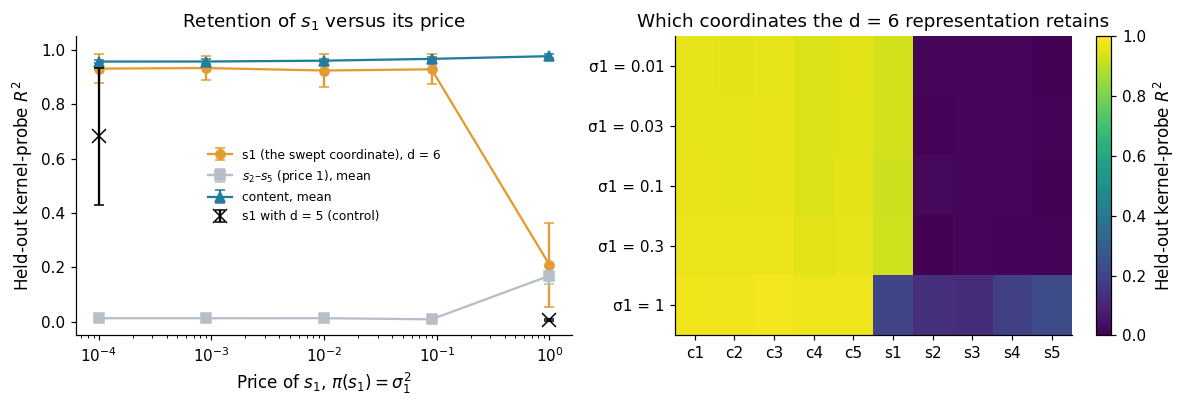

Saved Figure 1 to: /content/extension_soft_content/retention_curve.png


In [9]:
# Figure 1 only. No training or probe fitting is performed in this cell.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIGURE1_DIR = Path("extension_soft_content")
RESULTS_CSV = FIGURE1_DIR / "results.csv"
if "ext" in globals():
    plot_results = ext.copy()
elif RESULTS_CSV.is_file():
    plot_results = pd.read_csv(RESULTS_CSV)
else:
    raise FileNotFoundError(
        "Figure 1 needs the existing ext DataFrame or the original "
        "extension_soft_content/results.csv. Restore that CSV and rerun only "
        "this cell; do not rerun training merely to change figure labels."
    )

# Re-form the original summaries from full-precision, per-run results.
NC, NS, SPARE_SLOTS = 5, 5, 1
N = NC + NS
COORD_NAMES = [f"c{i+1}" for i in range(NC)] + [f"s{i+1}" for i in range(NS)]
nonlin_cols = [f"nonlin_{name}" for name in COORD_NAMES]
plot_results["content_mean"] = plot_results[[f"nonlin_c{i}" for i in range(1, NC + 1)]].mean(axis=1)
plot_results["others_mean"] = plot_results[[f"nonlin_s{i}" for i in range(2, NS + 1)]].mean(axis=1)
table = (plot_results.groupby(["rep_dim", "sigma1"])[nonlin_cols].mean()
         .rename(columns=lambda name: name.replace("nonlin_", "")))
sweep = plot_results[plot_results["rep_dim"] == NC + SPARE_SLOTS]
ctrl = plot_results[plot_results["rep_dim"] == NC]


def by_price(frame, column):
    """Mean and sample SD over seeds at each price (stored in column r1)."""
    return frame.groupby("r1")[column].agg(["mean", "std"]).reset_index()


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for column, label, marker, color in [
    ("nonlin_s1", f"s1 (the swept coordinate), d = {NC + SPARE_SLOTS}", "o", "#e49b32"),
    ("others_mean", r"$s_2$–$s_5$ (price 1), mean", "s", "#b7bec7"),
    ("content_mean", "content, mean", "^", "#227c9d"),
]:
    a = by_price(sweep, column)
    ax.errorbar(a["r1"], a["mean"], yerr=a["std"].fillna(0), marker=marker, color=color,
                capsize=3, label=label)
if len(ctrl):
    a = by_price(ctrl, "nonlin_s1")
    ax.errorbar(a["r1"], a["mean"], yerr=a["std"].fillna(0), fmt="x", markersize=9, color="black",
                capsize=3, zorder=5, label=f"s1 with d = {NC} (control)")
ax.set(xscale="log", xlabel=r"Price of $s_1$, $\pi(s_1)=\sigma_1^2$",
       ylabel=r"Held-out kernel-probe $R^2$", ylim=(-0.05, 1.05),
       title=r"Retention of $s_1$ versus its price")
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
heat = table.loc[NC + SPARE_SLOTS]
im = ax.imshow(heat.values, aspect="auto", vmin=0, vmax=1, cmap="viridis")
ax.set(xticks=range(N), xticklabels=COORD_NAMES, yticks=range(len(heat)),
       yticklabels=[f"σ1 = {s:g}" for s in heat.index],
       title=f"Which coordinates the d = {NC + SPARE_SLOTS} representation retains")
fig.colorbar(im, ax=ax, label=r"Held-out kernel-probe $R^2$")
fig.tight_layout()
FIGURE1_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE1_DIR / "retention_curve.png", dpi=150)
plt.show()
print("Saved Figure 1 to:", (FIGURE1_DIR / "retention_curve.png").resolve())
